Dependëncias:

In [ ]:
!pip uninstall -y tensorflow tensorflow-text tf-keras tensorflow-decision-forests ydf-tf keras keras-core keras-nlp
# Installing specific TensorFlow and tf-keras versions to ensure compatibility.
!pip install tensorflow==2.19.0 tf-keras==2.19.0 tensorflow-text==2.19.0 --quiet
!pip install -q pandas scikit-learn matplotlib seaborn
!pip install -q requests tqdm
!pip uninstall -y albumentations albucore
!pip install albumentations==1.4.8 albucore==0.0.15

Found existing installation: tensorflow 2.20.0
Uninstalling tensorflow-2.20.0:
  Successfully uninstalled tensorflow-2.20.0
Found existing installation: tensorflow-text 2.20.1
Uninstalling tensorflow-text-2.20.1:
  Successfully uninstalled tensorflow-text-2.20.1
Found existing installation: tf_keras 2.20.0
Uninstalling tf_keras-2.20.0:
  Successfully uninstalled tf_keras-2.20.0
Found existing installation: ydf_tf 2.20.0
Uninstalling ydf_tf-2.20.0:
  Successfully uninstalled ydf_tf-2.20.0
Found existing installation: keras 3.13.2
Uninstalling keras-3.13.2:
  Successfully uninstalled keras-3.13.2
Found existing installation: keras-nlp 0.26.0
Uninstalling keras-nlp-0.26.0:
  Successfully uninstalled keras-nlp-0.26.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 127.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Imports de bibliotecas, ferramentas e base de dados utilizados.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import albumentations as A
import tensorflow as tf
import cv2
import numpy as np
from matplotlib import pyplot as plt
import os
import pandas as pd

Mounted at /content/drive


Utilizando a biblioteca Pandas para montar o caminho das imagens que serão usadas no treinamento da CNN.

In [ ]:
TRAIN_DIR = '/content/drive/MyDrive/TCC1/colab_data/isic/train'
TEST_DIR = '/content/drive/MyDrive/TCC1/colab_data/isic/test'
CSV_PATH = '/content/drive/MyDrive/TCC1/colab_data/isic/metadata.csv'

# 1. Carrega o CSV original
df = pd.read_csv(CSV_PATH)

# 2. Lê os arquivos físicos
files_train = set(os.listdir(TRAIN_DIR))
files_test = set(os.listdir(TEST_DIR))

# 3. Cria uma coluna temporária no DataFrame para comparação (.jpg)
df['nome_com_extensao'] = df['isic_id'] + '.jpg'

# 4. SEPARAÇÃO EM DOIS DATAFRAMES
df_train = df[df['nome_com_extensao'].isin(files_train)].copy()
df_test = df[df['nome_com_extensao'].isin(files_test)].copy()

# =====================================================================
# 5. MAPEAMENTO DE CLASSES (A coluna 'label_int' PRECISA ser criada aqui!)
# =====================================================================
mapa_classes = {'Benign': 0, 'Indeterminate': 1, 'Malignant': 2}
df_train['label_int'] = df_train['diagnosis_1'].map(mapa_classes)
df_test['label_int'] = df_test['diagnosis_1'].map(mapa_classes)

# =====================================================================
# BALANCEAMENTO VIA OVERSAMPLING (DADOS EQUILIBRADOS ANTES DO TREINO)
# =====================================================================
print(f"Antes do Balanceamento - Treino: {df_train['diagnosis_1'].value_counts().to_dict()}")

# Encontra a quantidade da classe majoritária (Benign = 8471)
maior_classe_qtd = df_train['label_int'].value_counts().max()

# Replica as classes minoritárias para que fiquem com o mesmo tamanho da maior
df_balanced_list = []
for classe_id in range(3):
    df_da_classe = df_train[df_train['label_int'] == classe_id]

    # Se a classe for menor que a maioria, fazemos amostragem com reposição (duplica as fotos)
    df_classe_replicada = df_da_classe.sample(maior_classe_qtd, replace=True, random_state=42)
    df_balanced_list.append(df_classe_replicada)

# Junta tudo de volta e embaralha as linhas
df_train = pd.concat(df_balanced_list, axis=0).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Após o Balanceamento - Treino: {df_train['diagnosis_1'].value_counts().to_dict()}")
# =====================================================================

print(f"Imagens finais para Treino (Após Oversampling): {len(df_train)}")
print(f"Imagens encontradas para Teste: {len(df_test)}")

# 6. ONE-HOT ENCODING
labels_train_one_hot = tf.keras.utils.to_categorical(df_train['label_int'].values, num_classes=3)
labels_test_one_hot = tf.keras.utils.to_categorical(df_test['label_int'].values, num_classes=3)

# 7. CRIAÇÃO DOS CAMINHOS
file_path_train = [os.path.join(TRAIN_DIR, fname) for fname in df_train['nome_com_extensao']]
file_path_test = [os.path.join(TEST_DIR, fname) for fname in df_test['nome_com_extensao']]

# 8. CONSTRUÇÃO DOS DATASETS DO TENSORFLOW
train_dataset = tf.data.Dataset.from_tensor_slices((file_path_train, labels_train_one_hot))
test_dataset = tf.data.Dataset.from_tensor_slices((file_path_test, labels_test_one_hot))



Antes do Balanceamento - Treino: {'Benign': 8471, 'Malignant': 200, 'Indeterminate': 42}
Após o Balanceamento - Treino: {'Malignant': 8471, 'Benign': 8471, 'Indeterminate': 8471}
Imagens finais para Treino (Após Oversampling): 25413
Imagens encontradas para Teste: 2269


Criação do objeto Transform, o qual encapsula as regras de modificações que serão aplicadas às imagens

In [ ]:
# Definição das constantes
IMG_SIZE = 380  # Nativo do EfficientNetB4

train_transform = A.Compose([
    # 1. Redimensionamento para 380x380
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),

    # 2. Rotações, Espelhamentos e Cisalhamento (Shear)
    A.HorizontalFlip(p=0.5), # 50% de chance
    A.VerticalFlip(p=0.5),   # 50% de chance
    A.Rotate(limit=30, p=0.7), # Rotaciona até 30 graus
    # O cisalhamento (shear) no Albumentations é feito via Affine
    A.Affine(shear={'x': (-20, 20), 'y': (-20, 20)}, p=0.5, fit_output=False),

    # 3. CoarseDropout (Simula oclusões/pêlos/bolhas)
    # Cria até 8 buracos quadrados pretos na imagem
    A.CoarseDropout(
        max_holes=8,
        max_height=32,
        max_width=32,
        min_holes=2,
        min_height=8,
        min_width=8,
        fill_value=0, # Cor do buraco (0 = preto)
        p=0.5
    ),

    # 4. Normalização e Ajuste de Escala
    # Normaliza usando a média e desvio padrão do ImageNet
    # Converte os pixels de [0, 255] para float32
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
        max_pixel_value=255.0,
        p=1.0
    ),
])

Integração com o TensorFlow

In [ ]:
def aug_fn(image):
    """
    Função auxiliar que aplica as transformações de forma segura.
    Garante que o TensorFlow passe a imagem como um array NumPy puro.
    """
    # 1. Garante que a imagem está no formato NumPy e do tipo uint8 (esperado pelo Albumentations)
    img_np = np.array(image, dtype=np.uint8)

    # 2. Passa a imagem explicitamente usando o argumento 'image='
    aug_data = train_transform(image=img_np)

    # 3. Recupera a imagem transformada e converte para float32 (esperado pela EfficientNet)
    aug_img = aug_data["image"]
    return aug_img.astype(np.float32)

def process_data(file_path, label):
    # 1. Ler o arquivo de imagem
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)

    # 2. Aplicar o Albumentations via numpy_function
    # O TensorFlow chama a função python 'aug_fn'
    aug_img = tf.numpy_function(func=aug_fn, inp=[img], Tout=tf.float32)

    # 3. Recuperar a forma (Shape) do Tensor
    # O tf.numpy_function perde a informação de shape, precisamos redefinir
    aug_img.set_shape((IMG_SIZE, IMG_SIZE, 3))

    return aug_img, label

# 5. Criação do Dataset final do TensorFlow
train_dataset = tf.data.Dataset.from_tensor_slices((file_path_train, labels_train_one_hot))
test_dataset = tf.data.Dataset.from_tensor_slices((file_path_test, labels_test_one_hot))
train_dataset = train_dataset.map(process_data, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.map(process_data, num_parallel_calls=tf.data.AUTOTUNE)# Pipeline com Albumentations
train_dataset = train_dataset.batch(32).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(32).prefetch(tf.data.AUTOTUNE)


Calcula pesos das classes (Maligna, benigna e indeterminada)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

print("Calculando pesos das classes para balanceamento...")

# Pega os rótulos reais de treino (já que eles estão em formato inteiro 0, 1, 2)
y_train_inteiros = df_train['label_int'].values
classes_unicas = np.unique(y_train_inteiros)

# Calcula os pesos balanceados
pesos = compute_class_weight(
    class_weight='balanced',
    classes=classes_unicas,
    y=y_train_inteiros
)

# Converte para o formato de dicionário que o Keras exige
pesos_das_classes = {i: peso for i, peso in zip(classes_unicas, pesos)}

print("Pesos calculados:")
for classe, peso in pesos_das_classes.items():
    nome_classe = list(mapa_classes.keys())[list(mapa_classes.values()).index(classe)]
    print(f"Classe {nome_classe}: {peso:.2f}")

Calculando pesos das classes para balanceamento...
Pesos calculados:
Classe Benign: 0.34
Classe Indeterminate: 69.15
Classe Malignant: 14.52


Configuração de callbacks

In [ ]:
import os

# Diretório para salvar os resultados do TCC
SALVAMENTO_DIR = '/content/drive/MyDrive/TCC1/colab_data/isic/results'
os.makedirs(SALVAMENTO_DIR, exist_ok=True)

callbacks_list = [
    # 1. Salva automaticamente o melhor modelo no Drive ao longo das épocas
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SALVAMENTO_DIR, 'melhor_modelo_efficientnetb4.h5'),
        monitor='val_loss',         # Monitora a perda na validação
        save_best_only=True,        # Só substitui o arquivo se o modelo melhorar
        mode='min',
        verbose=1
    ),

    # 2. Interrompe o treinamento se o modelo parar de evoluir (Evita Overfitting)
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,                 # Se por 12 épocas a val_loss não cair, ele para
        restore_best_weights=True,  # Ao parar, recupera os pesos da melhor época
        verbose=1
    ),

    # 3. Reduz o Learning Rate se o treinamento estagnar em um patamar
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,                 # Multiplica o LR atual por 0.2 (reduz 5x)
        patience=5,                 # Espera 5 épocas de estagnação antes de reduzir
        min_lr=1e-6,
        verbose=1
    )
]

Implementando a arquitetura EfficientNetB4
-> Esse bloco deve ser rodado somente na primeira vez em que o modelo for executado.

In [ ]:
base_model = tf.keras.applications.EfficientNetB4(weights='imagenet', include_top=False, input_shape=(380, 380, 3))
base_model.trainable = False

x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)
model = tf.keras.Model(inputs=base_model.input, outputs=outputs)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Recall(name='recall')])

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Execução do modelo

In [ ]:
print("Iniciando Fase 1: Treinando o topo com classes balanceadas...")
history_fase1 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10,
    callbacks=callbacks_list,
    class_weight=pesos_das_classes
)

Iniciando Fase 1: Treinando o topo com classes balanceadas...
Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.2817 - loss: 1.3124 - recall: 0.0677
Epoch 1: val_loss improved from None to 1.33227, saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5



Epoch 1: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
273/273 ━━━━━━━━━━━━━━━━━━━━ 2246s 8s/step - accuracy: 0.3207 - loss: 1.2651 - recall: 0.0648 - val_accuracy: 0.1811 - val_loss: 1.3323 - val_recall: 0.0269 - learning_rate: 0.0010
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2739 - loss: 1.2539 - recall: 0.0960
Epoch 2: val_loss did not improve from 1.33227
273/273 ━━━━━━━━━━━━━━━━━━━━ 754s 3s/step - accuracy: 0.3475 - loss: 1.2122 - recall: 0.1130 - val_accuracy: 0.0674 - val_loss: 1.5096 - val_recall: 0.0194 - learning_rate: 0.0010
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2333 - loss: 1.3009 - recall: 0.0778
Epoch 3: val_loss improved from 1.33227 to 1.25703, saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5



Epoch 3: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
273/273 ━━━━━━━━━━━━━━━━━━━━ 778s 3s/step - accuracy: 0.3545 - loss: 1.1916 - recall: 0.1156 - val_accuracy: 0.1666 - val_loss: 1.2570 - val_recall: 0.0485 - learning_rate: 0.0010
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2956 - loss: 1.2410 - recall: 0.1125
Epoch 4: val_loss did not improve from 1.25703
273/273 ━━━━━━━━━━━━━━━━━━━━ 809s 3s/step - accuracy: 0.3752 - loss: 1.1822 - recall: 0.1423 - val_accuracy: 0.1353 - val_loss: 1.3166 - val_recall: 0.0520 - learning_rate: 0.0010
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2897 - loss: 1.2172 - recall: 0.1244
Epoch 5: val_loss did not improve from 1.25703
273/273 ━━━━━━━━━━━━━━━━━━━━ 815s 3s/step - accuracy: 0.3745 - loss: 1.1670 - recall: 0.1555 - val_accuracy: 0.1344 - val_loss: 1.3499 - val_recall: 0.0476 - learning_rate: 0.0010
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 


Epoch 7: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
273/273 ━━━━━━━━━━━━━━━━━━━━ 805s 3s/step - accuracy: 0.3913 - loss: 1.0861 - recall: 0.1481 - val_accuracy: 0.3147 - val_loss: 1.1048 - val_recall: 0.0956 - learning_rate: 2.0000e-04
Epoch 8/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3226 - loss: 1.0707 - recall: 0.1113
Epoch 8: val_loss improved from 1.10479 to 1.03783, saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5



Epoch 8: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
273/273 ━━━━━━━━━━━━━━━━━━━━ 754s 3s/step - accuracy: 0.4180 - loss: 1.0528 - recall: 0.1541 - val_accuracy: 0.3587 - val_loss: 1.0378 - val_recall: 0.1208 - learning_rate: 2.0000e-04
Epoch 9/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3758 - loss: 1.0508 - recall: 0.1432
Epoch 9: val_loss did not improve from 1.03783
273/273 ━━━━━━━━━━━━━━━━━━━━ 785s 3s/step - accuracy: 0.4328 - loss: 1.0585 - recall: 0.1758 - val_accuracy: 0.3658 - val_loss: 1.0803 - val_recall: 0.1463 - learning_rate: 2.0000e-04
Epoch 10/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.3379 - loss: 1.0832 - recall: 0.1422
Epoch 10: val_loss did not improve from 1.03783
273/273 ━━━━━━━━━━━━━━━━━━━━ 834s 3s/step - accuracy: 0.4090 - loss: 1.0793 - recall: 0.1707 - val_accuracy: 0.3200 - val_loss: 1.1334 - val_recall: 0.1084 - learning_rate: 2.0000e-04
Restoring model weights from 

Fase de Fine-Tunning

In [ ]:
print("Iniciando Fase 2: Fine-Tuning (Descongelamento das camadas profundas)...")

# 1. Descongela o modelo base por completo
base_model.trainable = True

camadas_para_descongelar = 50

# 2. Congela novamente as camadas iniciais e deixa apenas as últimas soltas
for layer in base_model.layers[:-camadas_para_descongelar]:
    layer.trainable = False

# 3. RECOMPILAÇÃO
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),  # LR bem pequeno!
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

# 4. Continua o treinamento de onde parou
print(f"Total de camadas agora treináveis: {len(model.trainable_variables)}")

history_fase2 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=30,
    callbacks=callbacks_list,
    class_weight=pesos_das_classes
)

Seguir o treinamento de onde foi interrompido ou pausado. Pega o último modelo salvo no drive.

In [ ]:
import tensorflow as tf

CAMINHO_MODELO_DRIVE = '/content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5'

print("Resgatando o modelo do Drive...")
model = tf.keras.models.load_model(CAMINHO_MODELO_DRIVE)
print("✅ Modelo carregado com sucesso!")

model.trainable = True
camadas_ativas = 53

for layer in model.layers[:-camadas_ativas]:
    layer.trainable = False

for layer in model.layers[-camadas_ativas:]:
    layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=tf.keras.losses.CategoricalFocalCrossentropy(gamma=2.0),
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

print("Reiniciando o Fine-Tuning...")
history_fase2_retomada = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=30,
    initial_epoch = 25,
    callbacks=callbacks_list
)

Fine tuning fase 3 onde aumentei a quantidade de camadas disponíveis para aprendizado.

In [ ]:
import tensorflow as tf

CAMINHO_MODELO_DRIVE = '/content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5'

print("Resgatando o modelo do Drive para Fase 3 (Deep Fine-Tuning)...")
model = tf.keras.models.load_model(CAMINHO_MODELO_DRIVE)

model.trainable = True

# DE 53 PARA 150 CAMADAS (Permite que a rede ajuste texturas médias e finas)
camadas_ativas = 150

for layer in model.layers[:-camadas_ativas]:
    layer.trainable = False

for layer in model.layers[-camadas_ativas:]:
    layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss=tf.keras.losses.CategoricalFocalCrossentropy(gamma=2.0), # Mantém a Focal Loss
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

print(f"Total de pesos/variáveis agora treináveis: {len(model.trainable_variables)}")

history_fase3 = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=70,
    initial_epoch=58,   # Continua de onde parou
    callbacks=callbacks_list
)

Resgatando o modelo do Drive para Fase 3 (Deep Fine-Tuning)...


Total de pesos/variáveis agora treináveis: 132
Epoch 59/70
795/795 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.7839 - loss: 0.0451 - recall: 0.6926
Epoch 59: val_loss improved from None to 0.05667, saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5



Epoch 59: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
795/795 ━━━━━━━━━━━━━━━━━━━━ 5050s 6s/step - accuracy: 0.7830 - loss: 0.0449 - recall: 0.6932 - val_accuracy: 0.6924 - val_loss: 0.0567 - val_recall: 0.6390 - learning_rate: 5.0000e-06
Epoch 60/70
795/795 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7879 - loss: 0.0441 - recall: 0.6996
Epoch 60: val_loss improved from 0.05667 to 0.04786, saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5



Epoch 60: finished saving model to /content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5
795/795 ━━━━━━━━━━━━━━━━━━━━ 1656s 2s/step - accuracy: 0.7896 - loss: 0.0441 - recall: 0.6996 - val_accuracy: 0.7497 - val_loss: 0.0479 - val_recall: 0.7007 - learning_rate: 5.0000e-06
Epoch 61/70
434/795 ━━━━━━━━━━━━━━━━━━━━ 10:37 2s/step - accuracy: 0.7920 - loss: 0.0441 - recall: 0.7045

________________________________________________________________________________________________
Geração de gráficos



In [ ]:
import matplotlib.pyplot as plt

# Extrai os dados do histórico
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

# Plota o Gráfico de Acurácia
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acurácia - Treino')
plt.plot(epochs_range, val_acc, label='Acurácia - Validação')
plt.legend(loc='lower right')
plt.title('Evolução da Acurácia')

# Plota o Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Perda - Treino')
plt.plot(epochs_range, val_loss, label='Perda - Validação')
plt.legend(loc='upper right')
plt.title('Evolução da Perda (Loss)')

# Salva o gráfico direto no Drive para usar no Word/LaTeX do TCC
plt.savefig(os.path.join(SALVAMENTO_DIR, 'curvas_aprendizado.png'), dpi=300)
plt.show()

Avaliação do modelo

In [ ]:
import tensorflow as tf
CAMINHO_MODELO_DRIVE = '/content/drive/MyDrive/TCC1/colab_data/isic/results/melhor_modelo_efficientnetb4.h5'

base_model = tf.keras.applications.EfficientNetB4(
    weights='imagenet',
    include_top=False,
    input_shape=(380, 380, 3)
)
x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)
model = tf.keras.Model(inputs=base_model.input, outputs=outputs)

try:
    model.load_weights(CAMINHO_MODELO_DRIVE, by_name=True, skip_mismatch=True)
    print("✅ Pesos carregados parcialmente (by_name=True).")
except Exception as e:
    print(f"Erro ao carregar pesos: {e}")

print("✅ Pesos carregados com sucesso no novo modelo!")

✅ Pesos carregados parcialmente (by_name=True).
✅ Pesos carregados com sucesso no novo modelo!


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print("Coletando previsões e rótulos...")

# 1. Garantir que as previsões sejam um array NumPy puro de inteiros
y_pred_probs = model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1).astype(int)

# 2. Coletar os rótulos reais de forma segura
# Usamos uma lista para armazenar os batches
y_true_list = []
for images, labels in test_dataset:
    # labels aqui já devem ser One-Hot [0, 1, 0]
    y_true_list.append(np.argmax(labels.numpy(), axis=1))

# Concatena todos os batches em um único array NumPy de inteiros
y_true = np.concatenate(y_true_list, axis=0).astype(int)

# 3. Verificação de sanidade (Printa os tipos para garantir)
print(f"Tipo de y_true: {y_true.dtype}, Tipo de y_pred: {y_pred.dtype}")
print(f"Shapes: y_true={y_true.shape}, y_pred={y_pred.shape}")

# 4. Gerar o relatório
target_names = ['Benign', 'Indeterminate', 'Malignant']
report = classification_report(y_true, y_pred, target_names=target_names)
print("\nRelatório de Classificação:\n", report)

Coletando previsões e rótulos...
71/71 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step
Tipo de y_true: int64, Tipo de y_pred: int64
Shapes: y_true=(2269,), y_pred=(2269,)

Relatório de Classificação:
                precision    recall  f1-score   support

       Benign       0.97      0.17      0.28      2203
Indeterminate       0.00      0.00      0.00         4
    Malignant       0.03      0.84      0.05        62

     accuracy                           0.18      2269
    macro avg       0.33      0.33      0.11      2269
 weighted avg       0.94      0.18      0.28      2269



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# 1. Relatório de Classificação (Precision, Recall/Sensibilidade, F1-Score)
target_names = ['Benign', 'Indeterminate', 'Malignant']
report = classification_report(y_true, y_pred, target_names=target_names)
print("Relatório de Classificação:\n", report)

# 2. Matriz de Confusão (essencial para extrair a Especificidade)
cm = confusion_matrix(y_true, y_pred)
print("Matriz de Confusão:\n", cm)

# 3. Cálculo da Especificidade
# A sensibilidade já está no relatório (Recall).
# A especificidade precisa ser calculada por classe manualmente:
def calcular_especificidade(cm):
    especificidades = []
    for i in range(len(cm)):
        tn = np.sum(cm) - (np.sum(cm[i, :]) + np.sum(cm[:, i]) - cm[i, i])
        fp = np.sum(cm[:, i]) - cm[i, i]
        especificidade = tn / (tn + fp)
        especificidades.append(especificidade)
    return especificidades

especificidades = calcular_especificidade(cm)
for i, classe in enumerate(target_names):
    print(f"Especificidade da classe {classe}: {especificidades[i]:.4f}")

Relatório de Classificação:
                precision    recall  f1-score   support

       Benign       0.97      0.17      0.28      2203
Indeterminate       0.00      0.00      0.00         4
    Malignant       0.03      0.84      0.05        62

     accuracy                           0.18      2269
    macro avg       0.33      0.33      0.11      2269
 weighted avg       0.94      0.18      0.28      2269

Matriz de Confusão:
 [[ 366    0 1837]
 [   1    0    3]
 [  10    0   52]]
Especificidade da classe Benign: 0.8333
Especificidade da classe Indeterminate: 1.0000
Especificidade da classe Malignant: 0.1663


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


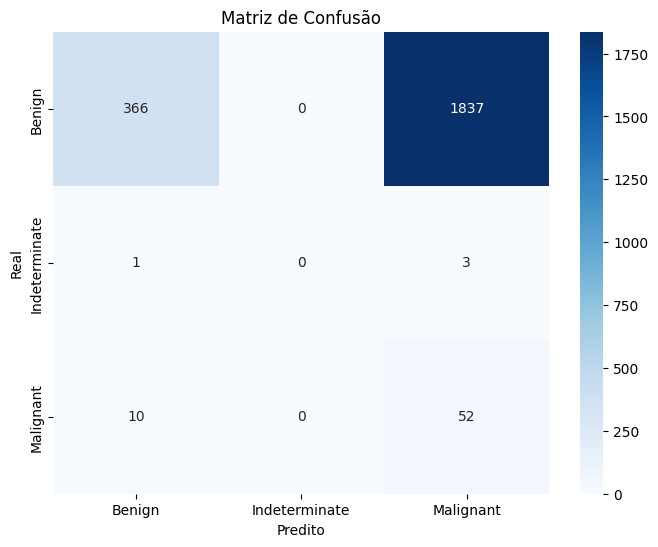

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.ylabel('Real')
plt.xlabel('Predito')
plt.title('Matriz de Confusão')
plt.show()